In [28]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Machine Learning models
from sklearn.linear_model import LinearRegression, Ridge, Lasso

# Pipeline and preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Feature selection
from sklearn.feature_selection import SelectKBest, f_regression

# Evaluation metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Multicollinearity
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Statistical analysis
import statsmodels.api as sm

In [29]:
df= pd.read_csv("d:\\project\\Multiple Linear Regression\\ToyotaCorolla - MLR.csv")

In [30]:
df.head()

,Price,Age_08_04,KM,Fuel_Type,HP,Automatic,cc,Doors,Cylinders,Gears,Weight
0,13500,23,46986,Diesel,90,0,2000,3,4,5,1165
1,13750,23,72937,Diesel,90,0,2000,3,4,5,1165
2,13950,24,41711,Diesel,90,0,2000,3,4,5,1165
3,14950,26,48000,Diesel,90,0,2000,3,4,5,1165
4,13750,30,38500,Diesel,90,0,2000,3,4,5,1170


In [31]:
df.dtypes

Price        int64
Age_08_04    int64
KM           int64
Fuel_Type      str
HP           int64
Automatic    int64
cc           int64
Doors        int64
Cylinders    int64
Gears        int64
Weight       int64
dtype: object

In [32]:
df.columns

Index(['Price', 'Age_08_04', 'KM', 'Fuel_Type', 'HP', 'Automatic', 'cc',
       'Doors', 'Cylinders', 'Gears', 'Weight'],
      dtype='str')

In [33]:
df.shape

(1436, 11)

In [34]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1436 entries, 0 to 1435
Data columns (total 11 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Price      1436 non-null   int64
 1   Age_08_04  1436 non-null   int64
 2   KM         1436 non-null   int64
 3   Fuel_Type  1436 non-null   str  
 4   HP         1436 non-null   int64
 5   Automatic  1436 non-null   int64
 6   cc         1436 non-null   int64
 7   Doors      1436 non-null   int64
 8   Cylinders  1436 non-null   int64
 9   Gears      1436 non-null   int64
 10  Weight     1436 non-null   int64
dtypes: int64(10), str(1)
memory usage: 131.9 KB


In [35]:
df.describe()

,Price,Age_08_04,KM,HP,Automatic,cc,Doors,Cylinders,Gears,Weight
count,1436.000000,1436.000000,1436.000000,1436.000000,1436.000000,1436.00000,1436.000000,1436.0,1436.000000,1436.00000
mean,10730.824513,55.947075,68533.259749,101.502089,0.055710,1576.85585,4.033426,4.0,5.026462,1072.45961
std,3626.964585,18.599988,37506.448872,14.981080,0.229441,424.38677,0.952677,0.0,0.188510,52.64112
min,4350.000000,1.000000,1.000000,69.000000,0.000000,1300.00000,2.000000,4.0,3.000000,1000.00000
25%,8450.000000,44.000000,43000.000000,90.000000,0.000000,1400.00000,3.000000,4.0,5.000000,1040.00000
50%,9900.000000,61.000000,63389.500000,110.000000,0.000000,1600.00000,4.000000,4.0,5.000000,1070.00000
75%,11950.000000,70.000000,87020.750000,110.000000,0.000000,1600.00000,5.000000,4.0,5.000000,1085.00000
max,32500.000000,80.000000,243000.000000,192.000000,1.000000,16000.00000,5.000000,4.0,6.000000,1615.00000


In [37]:
df.describe(include='object')

C:\Users\saniy\AppData\Local\Temp\ipykernel_30148\87514550.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object')


,Fuel_Type
count,1436
unique,3
top,Petrol
freq,1264


In [38]:
df.isnull().sum()

Price        0
Age_08_04    0
KM           0
Fuel_Type    0
HP           0
Automatic    0
cc           0
Doors        0
Cylinders    0
Gears        0
Weight       0
dtype: int64

In [39]:
df.duplicated().sum()

np.int64(1)

In [40]:
df = df.drop_duplicates()

print("Dataset shape after removing duplicates:", df.shape)

Dataset shape after removing duplicates: (1435, 11)


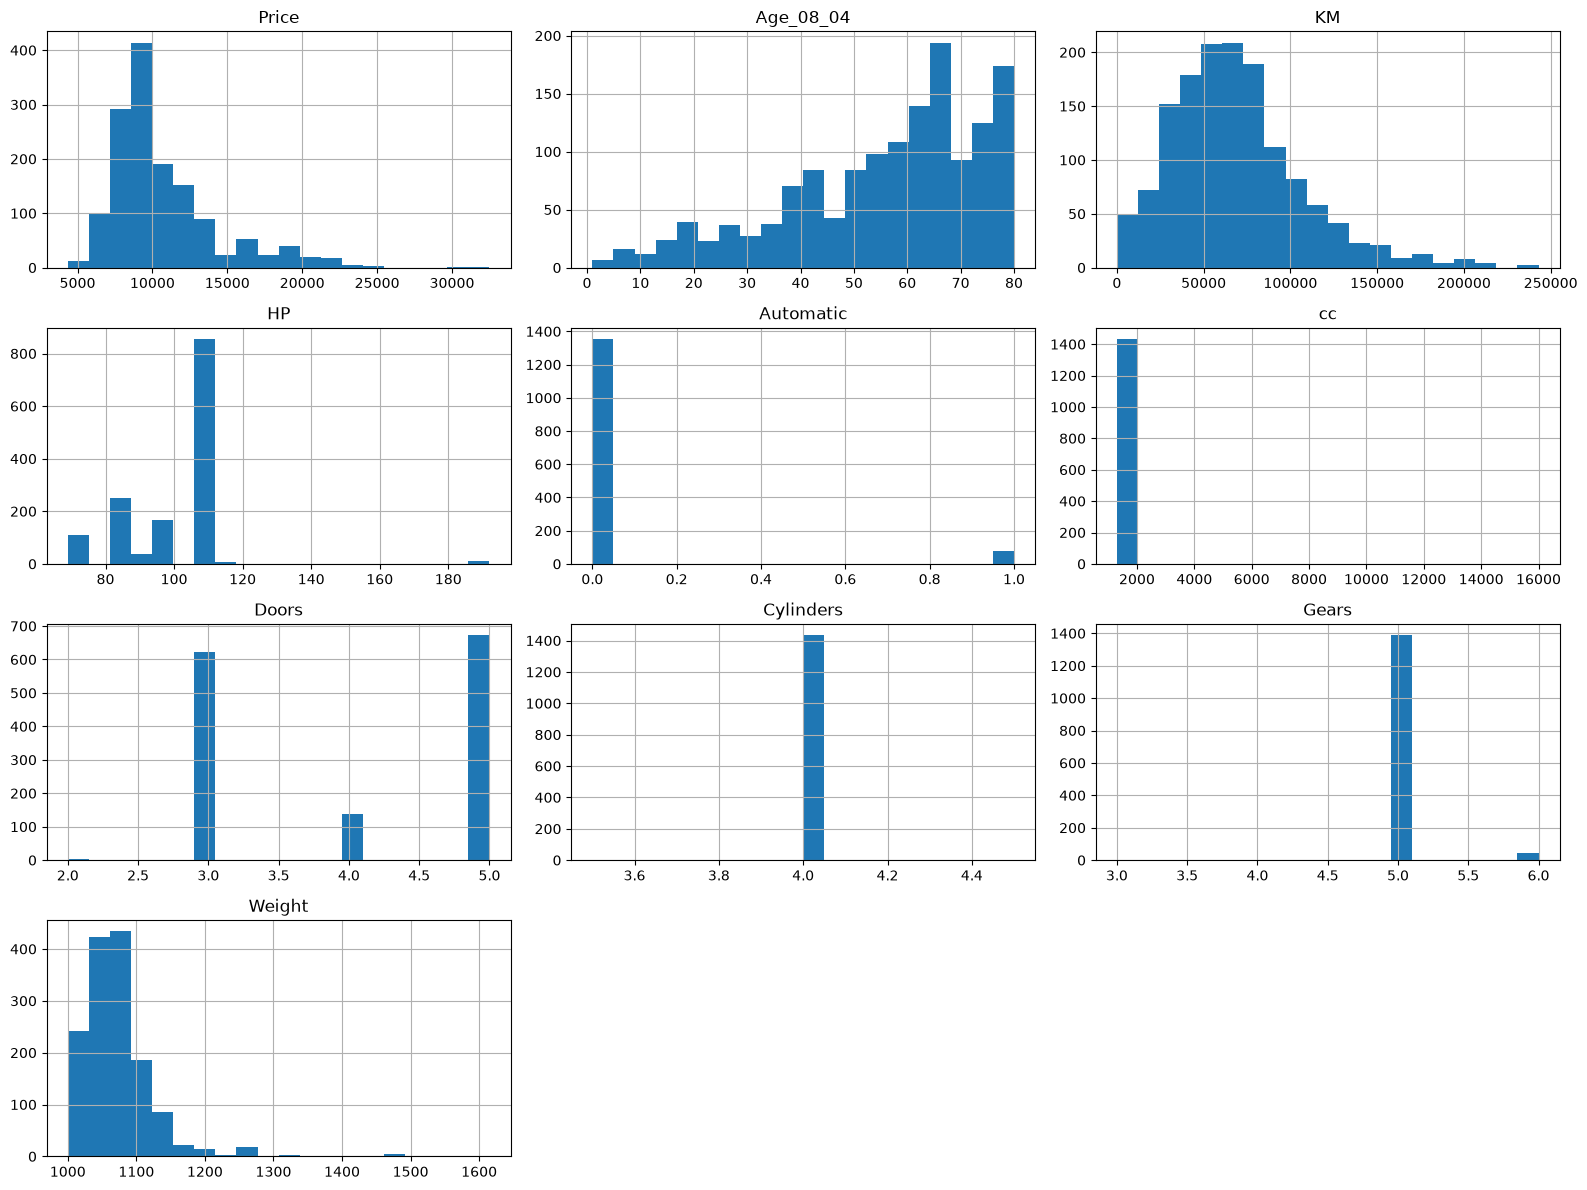

In [41]:
# Select numerical columns
num_cols = df.select_dtypes(include=np.number).columns

# Plot histograms
df[num_cols].hist(figsize=(16, 12), bins=20)

plt.tight_layout()
plt.show()

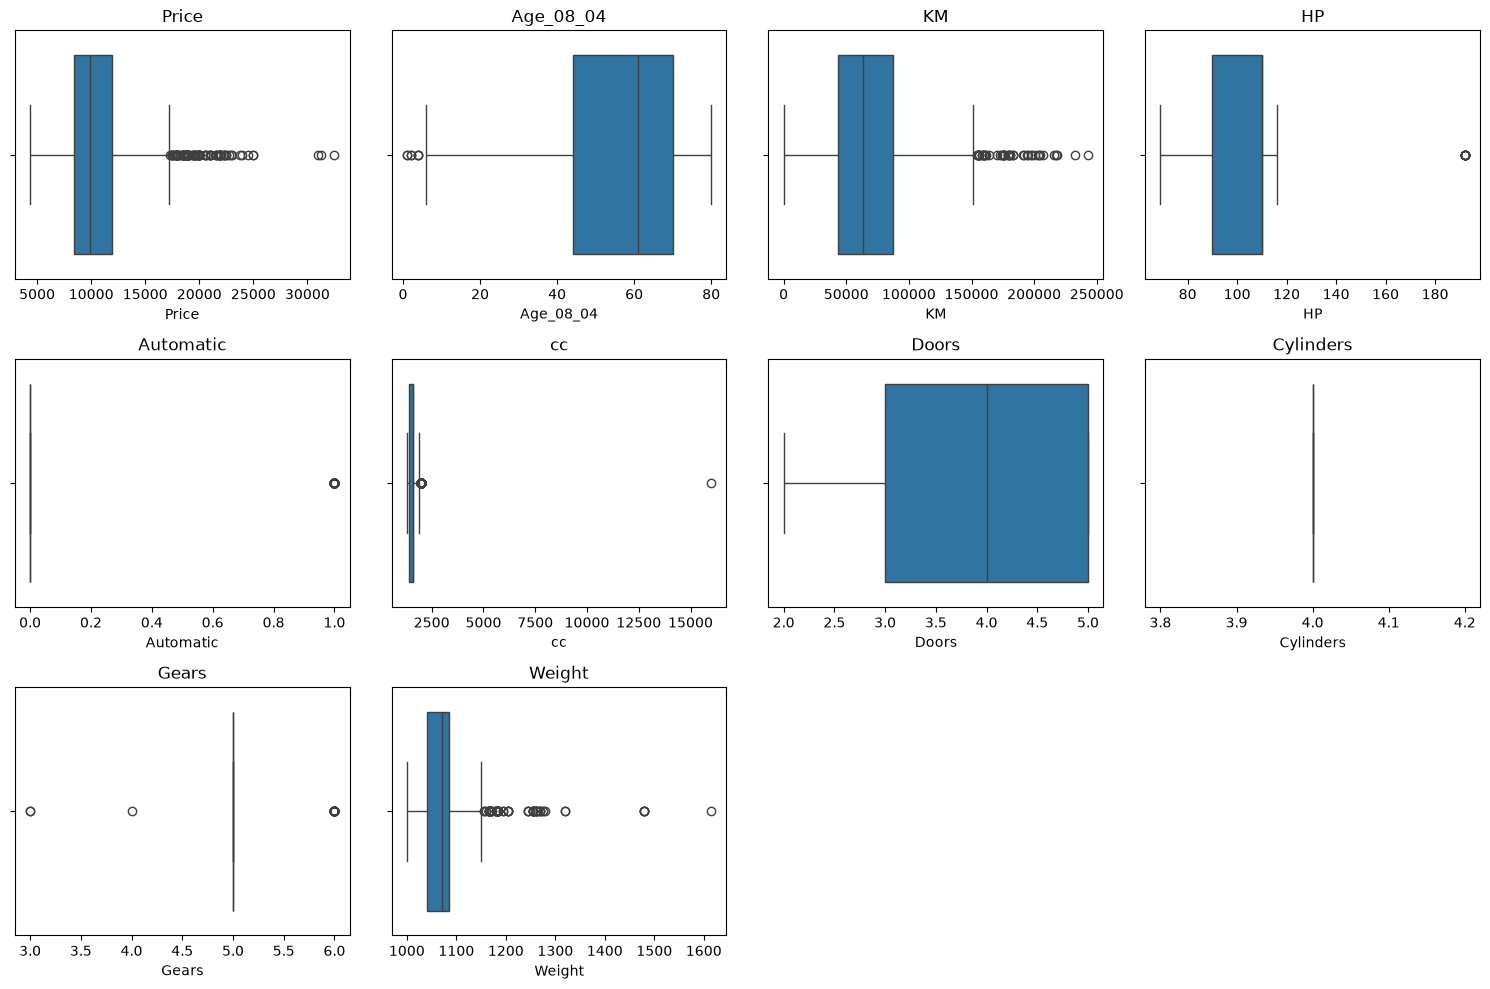

In [42]:
plt.figure(figsize=(15, 10))

for i, col in enumerate(num_cols, 1):
    plt.subplot(3, 4, i)
    sns.boxplot(x=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

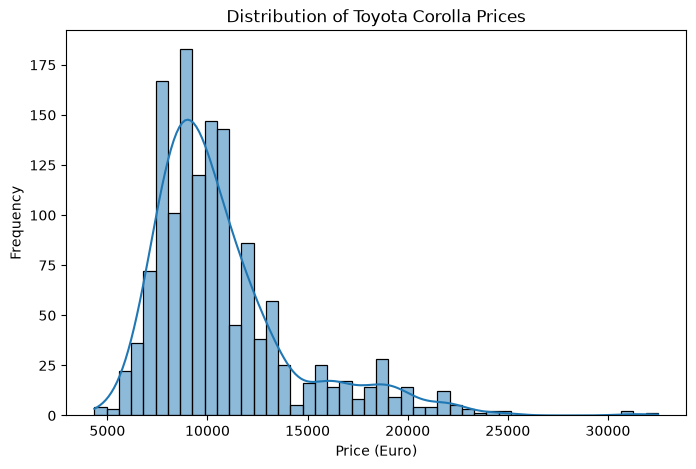

In [43]:
plt.figure(figsize=(8, 5))

sns.histplot(df['Price'], kde=True)

plt.title('Distribution of Toyota Corolla Prices')
plt.xlabel('Price (Euro)')
plt.ylabel('Frequency')

plt.show()

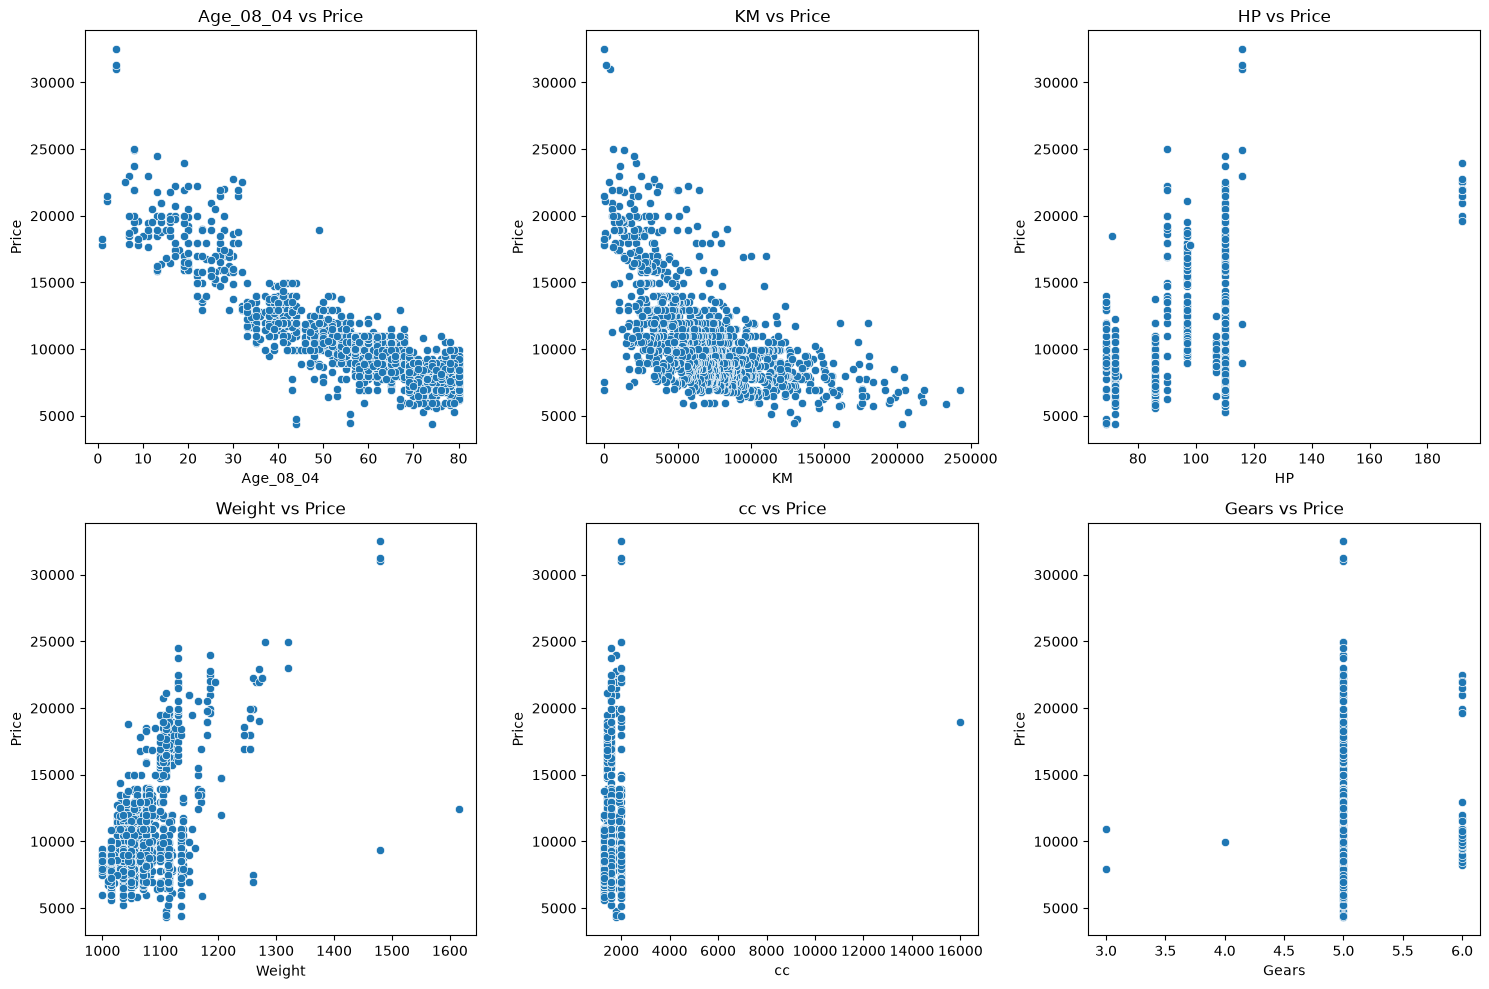

In [44]:
# Features to visualize against Price
features = ['Age_08_04', 'KM', 'HP', 'Weight', 'cc', 'Gears']

plt.figure(figsize=(15, 10))

for i, col in enumerate(features, 1):
    plt.subplot(2, 3, i)
    sns.scatterplot(data=df, x=col, y='Price')
    plt.title(f'{col} vs Price')

plt.tight_layout()
plt.show()

In [47]:
df.isnull().sum()

Price        0
Age_08_04    0
KM           0
Fuel_Type    0
HP           0
Automatic    0
cc           0
Doors        0
Cylinders    0
Gears        0
Weight       0
dtype: int64

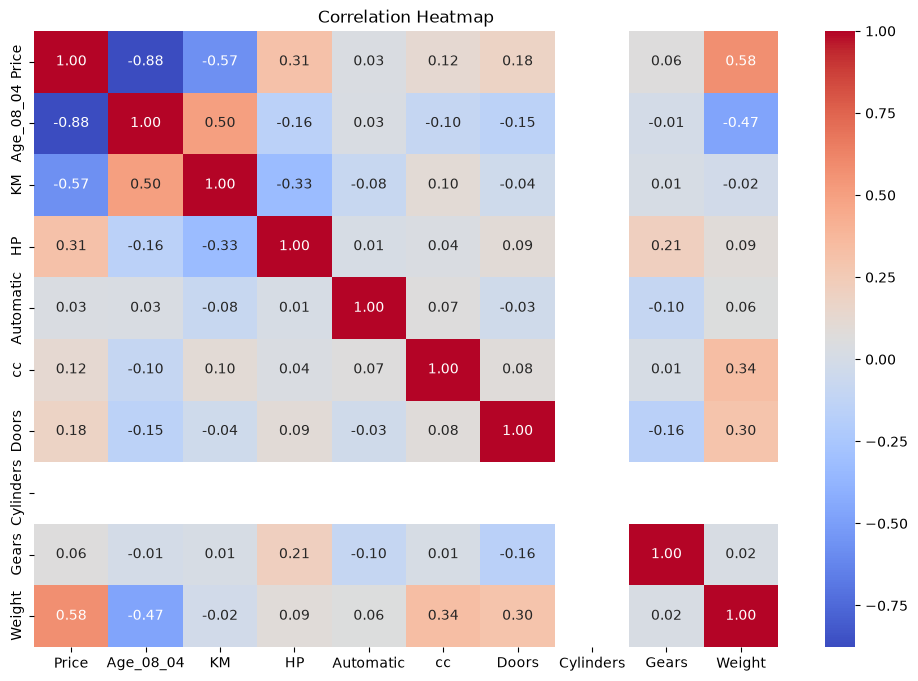

In [46]:
plt.figure(figsize=(12, 8))

corr = df.select_dtypes(include=np.number).corr()

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

In [48]:
# Target variable
y = df['Price']

# Independent variables
X = df.drop('Price', axis=1)

In [49]:
# Find columns having only one unique value
constant_cols = [col for col in X.columns if X[col].nunique() <= 1]

print("Constant columns:", constant_cols)

Constant columns: ['Cylinders']


In [50]:
# Remove constant columns
X = X.drop(columns=constant_cols)

In [51]:
categorical_cols = ['Fuel_Type', 'Doors']

# Convert categorical variables to string
for col in categorical_cols:
    X[col] = X[col].astype(str)

# Numerical columns
numerical_cols = [col for col in X.columns if col not in categorical_cols]

print("Numerical columns:", numerical_cols)
print("Categorical columns:", categorical_cols)

Numerical columns: ['Age_08_04', 'KM', 'HP', 'Automatic', 'cc', 'Gears', 'Weight']
Categorical columns: ['Fuel_Type', 'Doors']


In [52]:
# Preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_cols)
    ]
)

In [53]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1148, 9)
Testing data: (287, 9)


In [54]:
# Model 1: Multiple Linear Regression with all features

model1 = Pipeline([
    ('preprocessing', preprocessor),
    ('regressor', LinearRegression())
])

# Train model
model1.fit(X_train, y_train)

# Predict test data
y_pred1 = model1.predict(X_test)

In [55]:
# Select important features
selected_features = [
    'Age_08_04',
    'KM',
    'HP',
    'Weight',
    'Automatic',
    'Fuel_Type'
]

# Separate selected numerical and categorical features
selected_num = [
    'Age_08_04',
    'KM',
    'HP',
    'Weight',
    'Automatic'
]

selected_cat = ['Fuel_Type']

# Preprocessing for selected features
preprocessor2 = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), selected_num),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), selected_cat)
    ]
)

# Create Model 2
model2 = Pipeline([
    ('preprocessing', preprocessor2),
    ('regressor', LinearRegression())
])

# Train model
model2.fit(X_train[selected_features], y_train)

# Predict
y_pred2 = model2.predict(X_test[selected_features])

In [56]:
# Model 3: Feature selection with SelectKBest

model3 = Pipeline([
    ('preprocessing', preprocessor),
    ('feature_selection', SelectKBest(score_func=f_regression, k=8)),
    ('regressor', LinearRegression())
])

# Train
model3.fit(X_train, y_train)

# Predict
y_pred3 = model3.predict(X_test)

In [57]:
def evaluate_model(y_true, y_pred, model_name):

    # Mean Absolute Error
    mae = mean_absolute_error(y_true, y_pred)

    # Mean Squared Error
    mse = mean_squared_error(y_true, y_pred)

    # Root Mean Squared Error
    rmse = np.sqrt(mse)

    # R-squared
    r2 = r2_score(y_true, y_pred)

    return {
        'Model': model_name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2': r2
    }

In [58]:
# Evaluate all three models
results = [
    evaluate_model(y_test, y_pred1, 'MLR - All Features'),
    evaluate_model(y_test, y_pred2, 'MLR - Selected Features'),
    evaluate_model(y_test, y_pred3, 'MLR - SelectKBest')
]

# Convert results to DataFrame
results_df = pd.DataFrame(results)

# Sort based on RMSE
results_df = results_df.sort_values(by='RMSE')


results_df

,Model,MAE,MSE,RMSE,R2
2,MLR - SelectKBest,982.878392,1.945885e+06,1394.949939,0.837804
1,MLR - Selected Features,987.502744,2.150047e+06,1466.303734,0.820787
0,MLR - All Features,979.628781,2.185026e+06,1478.183355,0.817871


In [59]:
# Ridge Regression
ridge_model = Pipeline([
    ('preprocessing', preprocessor),
    ('regressor', Ridge(alpha=1.0))
])

# Train
ridge_model.fit(X_train, y_train)

# Predict
ridge_pred = ridge_model.predict(X_test)

# Evaluate
ridge_result = evaluate_model(
    y_test,
    ridge_pred,
    'Ridge Regression'
)

ridge_result

{'Model': 'Ridge Regression',
 'MAE': 979.8501549760871,
 'MSE': 2175883.3034041105,
 'RMSE': np.float64(1475.087557877196),
 'R2': 0.8186330714660093}

In [60]:
# Lasso Regression
lasso_model = Pipeline([
    ('preprocessing', preprocessor),
    ('regressor', Lasso(alpha=1.0, max_iter=10000))
])

# Train
lasso_model.fit(X_train, y_train)

# Predict
lasso_pred = lasso_model.predict(X_test)

# Evaluate
lasso_result = evaluate_model(
    y_test,
    lasso_pred,
    'Lasso Regression'
)

lasso_result

{'Model': 'Lasso Regression',
 'MAE': 979.0867876866108,
 'MSE': 2170040.8172326726,
 'RMSE': np.float64(1473.1058404719847),
 'R2': 0.8191200616323745}

In [61]:
alphas = [0.01, 0.1, 1, 10, 100]

ridge_results = []
lasso_results = []

for alpha in alphas:

    # Ridge
    ridge = Pipeline([
        ('preprocessing', preprocessor),
        ('regressor', Ridge(alpha=alpha))
    ])

    ridge.fit(X_train, y_train)
    ridge_pred = ridge.predict(X_test)

    ridge_results.append(
        evaluate_model(y_test, ridge_pred, f'Ridge alpha={alpha}')
    )

    # Lasso
    lasso = Pipeline([
        ('preprocessing', preprocessor),
        ('regressor', Lasso(alpha=alpha, max_iter=10000))
    ])

    lasso.fit(X_train, y_train)
    lasso_pred = lasso.predict(X_test)

    lasso_results.append(
        evaluate_model(y_test, lasso_pred, f'Lasso alpha={alpha}')
    )

# Combine results
regularization_results = pd.DataFrame(
    ridge_results + lasso_results
)

regularization_results.sort_values(by='RMSE')

,Model,MAE,MSE,RMSE,R2
9,Lasso alpha=100,973.109721,1.879463e+06,1370.934913,0.843341
4,Ridge alpha=100,984.259752,1.962269e+06,1400.810015,0.836439
8,Lasso alpha=10,977.144713,2.053941e+06,1433.157573,0.828797
3,Ridge alpha=10,981.027487,2.111030e+06,1452.938298,0.824039
7,Lasso alpha=1,979.086788,2.170041e+06,1473.105840,0.819120
2,Ridge alpha=1,979.850155,2.175883e+06,1475.087558,0.818633
6,Lasso alpha=0.1,979.479072,2.183405e+06,1477.634943,0.818006
1,Ridge alpha=0.1,979.632530,2.184021e+06,1477.843283,0.817955
5,Lasso alpha=0.01,979.613808,2.184864e+06,1478.128467,0.817885
0,Ridge alpha=0.01,979.628613,2.184923e+06,1478.148588,0.817880


In [62]:
# Combine the three MLR results with Ridge and Lasso
all_results = results + [ridge_result, lasso_result]

final_results = pd.DataFrame(all_results)

# Sort models from lowest RMSE to highest
final_results = final_results.sort_values(by='RMSE')

final_results

,Model,MAE,MSE,RMSE,R2
2,MLR - SelectKBest,982.878392,1.945885e+06,1394.949939,0.837804
1,MLR - Selected Features,987.502744,2.150047e+06,1466.303734,0.820787
4,Lasso Regression,979.086788,2.170041e+06,1473.105840,0.819120
3,Ridge Regression,979.850155,2.175883e+06,1475.087558,0.818633
0,MLR - All Features,979.628781,2.185026e+06,1478.183355,0.817871


In [63]:
# Get transformed feature names after preprocessing
feature_names = model1.named_steps['preprocessing'].get_feature_names_out()

# Get regression coefficients
coefficients = model1.named_steps['regressor'].coef_

# Create coefficient DataFrame
coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})

# Sort by coefficient
coef_df = coef_df.sort_values(by='Coefficient', ascending=False)

coef_df

,Feature,Coefficient
6,num__Weight,1391.810581
8,cat__Fuel_Type_Petrol,1181.700623
2,num__HP,209.842126
5,num__Gears,86.542849
3,num__Automatic,45.381038
4,num__cc,-22.723575
10,cat__Doors_4,-331.584845
7,cat__Fuel_Type_Diesel,-494.779619
9,cat__Doors_3,-597.120536
1,num__KM,-603.552232


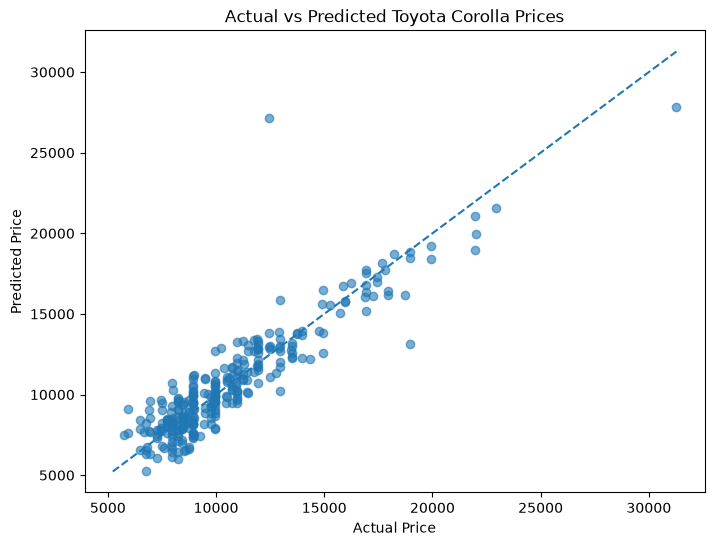

In [64]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred1, alpha=0.6)

# Reference diagonal line
min_value = min(y_test.min(), y_pred1.min())
max_value = max(y_test.max(), y_pred1.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--'
)

plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Actual vs Predicted Toyota Corolla Prices')

plt.show()

In [65]:
# Calculate residuals
residuals = y_test - y_pred1

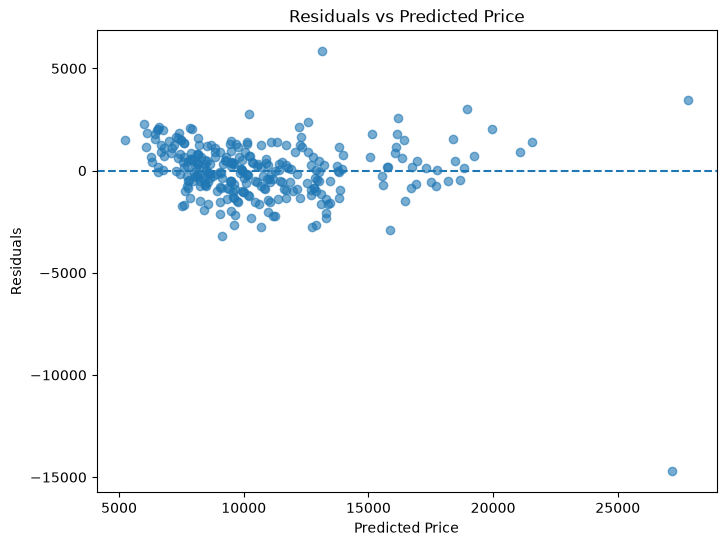

In [66]:
plt.figure(figsize=(8, 6))

plt.scatter(y_pred1, residuals, alpha=0.6)

plt.axhline(y=0, linestyle='--')

plt.xlabel('Predicted Price')
plt.ylabel('Residuals')
plt.title('Residuals vs Predicted Price')


plt.show()

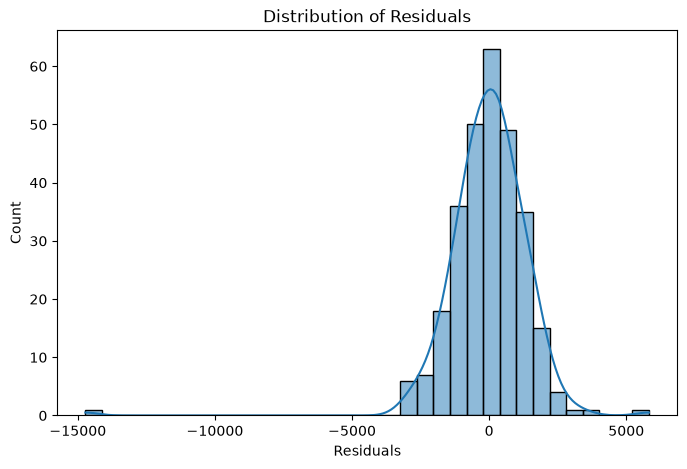

In [67]:
plt.figure(figsize=(8, 5))

sns.histplot(residuals, kde=True)

plt.title('Distribution of Residuals')
plt.xlabel('Residuals')


plt.show()

# Interview Questions


* Normalization is the process of organizing data into structures, related tables to reduce data redundancy and prevent data anomalies. It helps scaling values into a fixed range, often between 0 adn 1.

* Standardization is the process of creating and applying uniform rules, specifications, or procedure so that products, processes or data remain consistent across different people, system, or locations

* Multicollinearity occures when two or more independent variables are strongly related to each other


*To deal with multicollinearity in regression, either leave the model as it is for pure prediction, remove or combine redundant predictors, or apply regularization methods like Ridge or Lasso regression.*